<a href="https://colab.research.google.com/github/Juliusp36/GinyuForce2/blob/main/01_ratings_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7 Exercises
**1. In the toy matrix, identify all eight missing entries by user and movie. Give a predicted rating for each and justify two of your predictions using similar users or similar movies.**

All of the users have at lease 1 missing entry. Ana is missing an entry for Romance 2; Ben is missing an entry for Action 2; Cal is missing an entry for Action 3 and Romance 3; Dee is missing an entry for Romance 3;Eve is missing an entry for Action 1; Fay is missing an entry for Action 3 and Romance 2.

Predictions:

Ana - Romance 2: 1.0 averaging their previous ratings in the same category

Ben - Action 2: 4.0 averaging their previous ratings in the same category

Cal - Action 3: 5.0 because of those with higher Action movie scores (Ana and Ben), Action movie 3 is rated the highest, Romance 3: By taking into account he shares similar preferences to Ana and Ben, It is safe to say that Cal's Romance 3 rating would be a 1.0

Dee - Romance 3: When viewing Dee's other interests, romance, and by looking at the romace preferences of Eve and Fay, we can predict that his rating would be 4.0

Eve - Action 1: 1.0 by averaging their previous ratings in the same category

Fay - Action 3: 1.0 by averageing the Action 3 ratings of Dee and Eve, Romance 3: 5.0 based on their  

**2. Add a seventh imaginary user who likes action movies and dislikes romance movies. Choose at least four ratings for this user, include two missing ratings, and explain what you would predict for them.**

```python
[5, 5, np.nan, np.nan, 1, 1]# Jerry

```

For Jerry, I would predict that for Action movie 3 he rates it 5.0 not only because of his previous ratings but because Action movie 3 is rated a 5 among those who both like Action movies and have seen Action movie 3 already. I would also predict that he rates Romance 1 a 1.0 due to his previous ratings.

**3. What does the command np.isnan(toy).sum() compute? Write a different line of code that computes the fraction of missing entries in toy.**

The command looks for values within the dataframe that are NaN (not a number) and produces a sum of them.

to produce the fraction, use:

```python
np.isnan(toy).mean()
```
Which takes the sum of NaN values over the total count of the entries. This will produce 0.222 resulting from 8/36.

**4. Use the data frame ratings to find the least common star rating. State both the rating and its number of occurrences.**

Looking at the plot, I deduced that the least common star rating was 1 and then used this line of code to determine that the count was 6110:

```python
least_star_count = (ratings["rating"]==1).sum()
print(least_star_count)
```

**5. Find the average rating for each user using groupby. Which user has the highest average rating? Why should we be cautious about calling that person the “most positive” user?**

The highest rating is 737. This is potentially dangerous because the nature of the line:

```python
per_user = ratings.groupby("user").size()
```

Is specifically counting how many times that user has rated. It does not search for their actual ratings or the highest count of 5 star ratings; it could be possible that the user has all 1.0 ratings which would not make them the most positive user.

**6. In your own words, distinguish between the raw table ratings and the matrix R. What does one row mean in each object?**

The original data has one row per rating, however, by using the pivot table in R, we have one row per user with multiple columns for each movie rating.

**7. Suppose that the rating matrix had no missing entries. Explain why the SVD would then be computationally possible, and explain why it still might not immediately solve the recommendation problem.**

The requirement for SVD in numpy specifically is that all values in the datset must be filled and not a NaN. It is computationally possible to perform the SVD with numpy if all values are filled, but due to hidden factors, the problem may not be fully solved.

**8. List three possible hidden factors that could affect movie ratings. For each factor, describe what a high value might mean for a user and for a movie.**

Personal mood, personal ideologies, actor preference

Mood - If a person's mood is high on the day they watch the film, they may rate it higher

Ideologies - If the film aligns with the person's religous or political beliefs they may rate it higher

Actor Preference - Individuals who like the actors within a movie may be more likely to rate it higher, regardless of the true quality of the film

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Explaination - standard inputs used for this class. Refer to python libraries which give us specific computational abilities.

In [3]:
movies = ["Action 1", "Action 2", "Action 3",
"Romance 1", "Romance 2", "Romance 3"]
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]

Explaination - A list of movies and users to be used in the rating matrix

In [4]:
toy = np.array([
[5, 4, 5, 1, np.nan, 2], # Ana
[4, np.nan, 5, 2, 1, 1], # Ben
[5, 5, np.nan, 1, 2, np.nan], # Cal
[1, 2, 1, 5, 4, np.nan], # Dee
[np.nan, 1, 2, 4, 5, 5], # Eve
[2, 1, np.nan, 5, np.nan, 4], # Fay
])

 Explaination - The ratings of each user associated with the movies

In [5]:
toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Ana,5.0,4.0,5.0,1.0,NaN,2.0
Ben,4.0,NaN,5.0,2.0,1.0,1.0
Cal,5.0,5.0,NaN,1.0,2.0,NaN
Dee,1.0,2.0,1.0,5.0,4.0,NaN
Eve,NaN,1.0,2.0,4.0,5.0,5.0
Fay,2.0,1.0,NaN,5.0,NaN,4.0


Explaination - Here we see a combination of the above two cells. The users, their ratings, and the movies

In [9]:
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


Explaination - Returns the sum of NaN values in the rankings matrix along with the number of entries in total

In [10]:
import os
import urllib.request
import zipfile

if not os.path.exists("ml-100k"):
  urllib.request.urlretrieve(
  "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
  "ml-100k.zip"
  )
  zipfile.ZipFile("ml-100k.zip").extractall()

Explaination - Finds the ml-100k database from online and downloads it

In [11]:
ratings = pd.read_csv(
"ml-100k/u.data",
sep="\t",
names=["user", "item", "rating", "time"]
)
ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Explaination - Creates a dataframe of the ml-100k dataset and then returns the head (first few entries)

In [12]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


Explaination - Prints the number of ratings, users, and movies

In [13]:
star_counts = ratings["rating"].value_counts().sort_index()
star_counts
average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

Average rating: 3.53


Explaination - Returns the average rating found within the datset

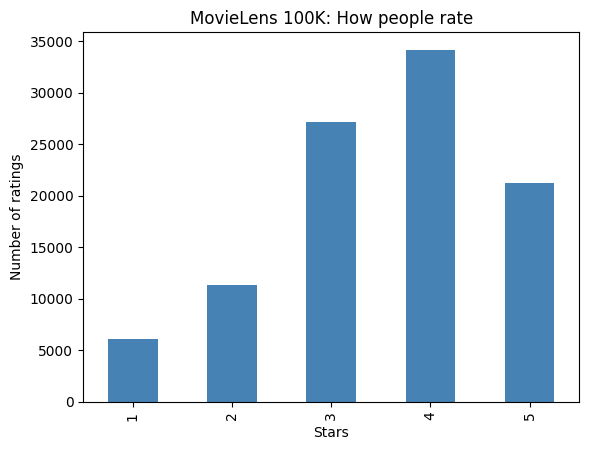

In [14]:
star_counts.plot(kind="bar", color="steelblue")
plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
plt.show()

Explaination - A plot with the star ratings and their counts

In [22]:
R = ratings.pivot_table(
index="user",
columns="item",
values="rating"
)

Explaination - Produces a pivot table for the ml-100k ratings matrix to manipulate the data so that each user is a row.

In [21]:
print("Matrix shape:", R.shape)
fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing: 0.937


Explaination - Returns the shape of the matrix and fraction of the missin values within the matrix

In [18]:
per_user = ratings.groupby("user").size()
print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


Explaination - Returns the number of ratings produces by the least, median, and most active user.

In [23]:
titles = pd.read_csv(
"ml-100k/u.item",
sep="|",
encoding="latin-1",
header=None,
usecols=[0, 1],
names=["item", "title"]
)

 Explaination - Produces a dataframe from the ml-100k dataset with the movie titles

In [24]:
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))
top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


Explaination - Returns a table of thre top 5 films, their number of ratings, and their average rating